In [46]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import linkage, dendrogram

In [47]:
df = pd.read_csv("./data/Telco_customer_churn.csv")
df.head()

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,...,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,...,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


In [48]:
features = [
    'Tenure Months',
    'Monthly Charges',
    "Total Charges"
]

X = df[features].copy()

In [49]:
for column in features:
    X[column] = pd.to_numeric(X[column], errors='coerce')

In [50]:
X = X.replace([np.inf, -np.inf], np.nan)
X = X.dropna()

clustered_data = df.loc[X.index].copy()

print("Rows available after cleaning : ", len(X))

Rows available after cleaning :  7032


In [51]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("After scaling X Shape : ", X.shape)
X_scaled

After scaling X Shape :  (7032, 3)


array([[-1.23950408, -0.36392329, -0.95964911],
       [-1.23950408,  0.19617818, -0.94045745],
       [-0.99504031,  1.15848901, -0.64536922],
       ...,
       [ 1.61257321,  1.27649259,  2.24105565],
       [-0.87280842, -1.17000405, -0.85451414],
       [ 1.36810945,  1.35793167,  2.01234407]], shape=(7032, 3))

In [52]:
sample_size = min(1500, len(X_scaled))

rng = np.random.default_rng(42)

sample_indices = rng.choice(
    len(X_scaled),
    size=sample_size,
    replace=False 
)

X_sample = X_scaled[sample_indices]
linkage_matrix = linkage(X_sample, method="ward")

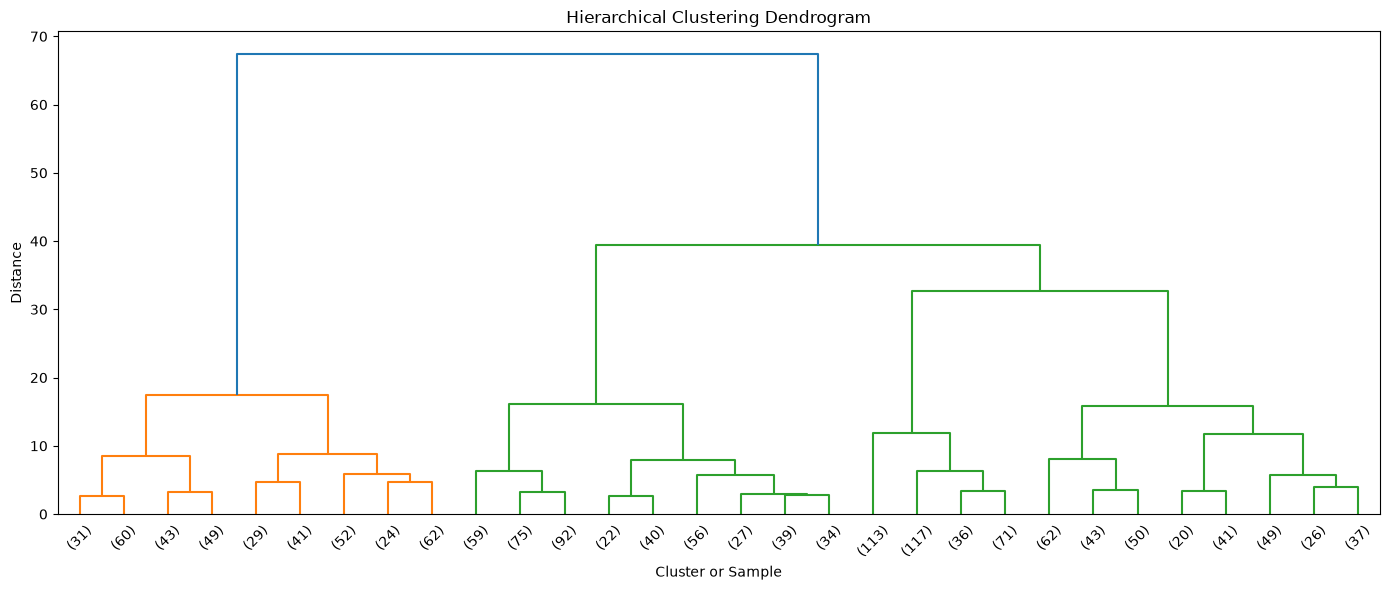

In [53]:
plt.figure(figsize=(14, 6))

dendrogram(
    linkage_matrix,
    truncate_mode="lastp",
    p=30,
    leaf_rotation=45,
    leaf_font_size=10
)

plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Cluster or Sample")
plt.ylabel("Distance")
plt.tight_layout()
plt.show()

In [54]:
n_clusters = 4

model = AgglomerativeClustering(
    n_clusters=n_clusters,
    linkage="ward"
)

cluster_labels = model.fit_predict(X_scaled)
clustered_data["Cluster"] = cluster_labels

print(clustered_data["Cluster"].value_counts().sort_index())

Cluster
0    1838
1    1846
2    2003
3    1345
Name: count, dtype: int64


In [55]:
score = silhouette_score(
    X_scaled,
    cluster_labels,
    sample_size=min(2000, len(X_scaled )),
    random_state=42
)

print("Silhouette Score : ", score)

Silhouette Score :  0.3844518393217676


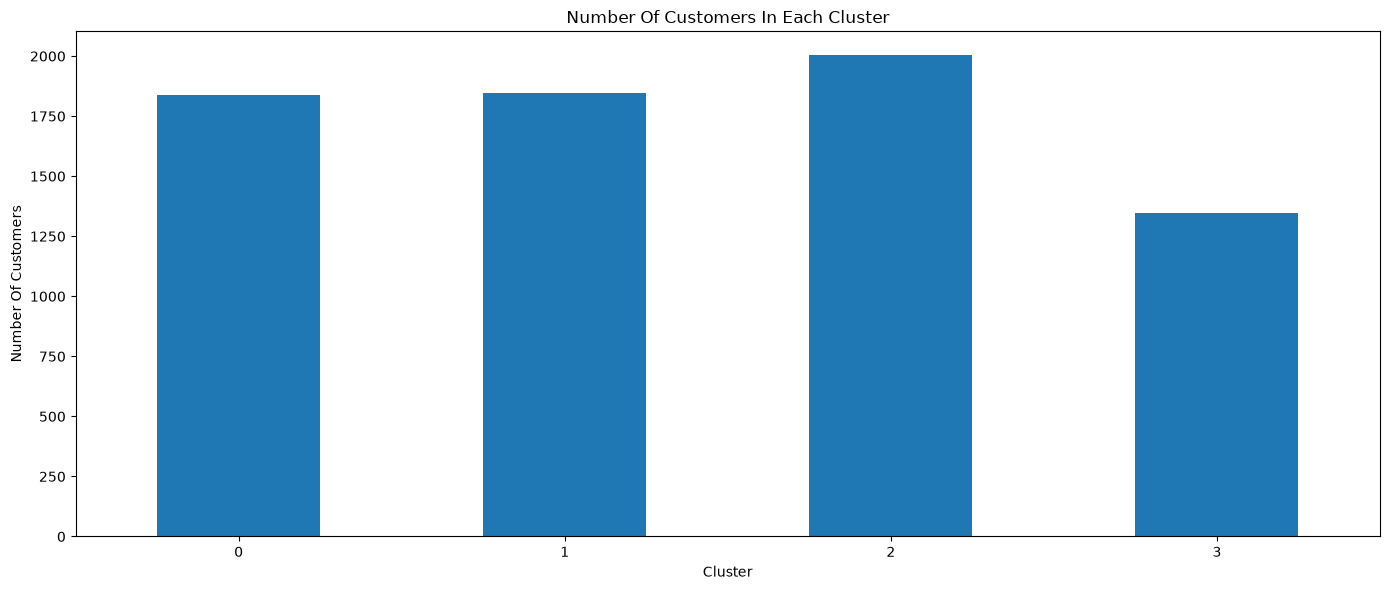

In [56]:
cluster_counts = clustered_data["Cluster"].value_counts().sort_index()
plt.figure(figsize=(14, 6))

cluster_counts.plot(kind='bar')

plt.title("Number Of Customers In Each Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number Of Customers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [57]:
clustered_data[features] = X[features]
cluster_profile = clustered_data.groupby("Cluster")[features].mean()
print("Cluster Profile Mean : ", cluster_profile.round(2))

if "Churn Label" in clustered_data.columns:
    churn_distribution = pd.crosstab(
        clustered_data['Cluster'],
        clustered_data['Churn Label'],
        normalize="index"
    ) * 100

print(churn_distribution.round(2))

print("Churn Counts within each cluster : ")
print(
    pd.crosstab(
        clustered_data['Cluster'],
        clustered_data['Churn Label']
    )
)

Cluster Profile Mean :           Tenure Months  Monthly Charges  Total Charges
Cluster                                               
0                28.35            23.04         652.09
1                41.30            76.36        2976.93
2                 8.23            69.28         553.17
3                61.83            99.32        6136.96
Churn Label     No    Yes
Cluster                  
0            88.08  11.92
1            77.14  22.86
2            49.78  50.22
3            83.49  16.51
Churn Counts within each cluster : 
Churn Label    No   Yes
Cluster                
0            1619   219
1            1424   422
2             997  1006
3            1123   222
